# CSIP Module 10: System Dynamics & World Model State Transition
**Computational Society Intelligence Platform (CSIP) — Behavioral Decision Intelligence (BDI)**

### SKKNI Data Science Competency Standards
- **[UK-08 Membangun Skenario Model]**: Perumusan model dinamika sistem state-space dan pengujian skenario intervensi.
- **[UK-09 Membangun Model]**: Estimasi parameter Vector AutoRegressive State Transition Matrix $\Phi$.
- **[UK-10 Mengevaluasi Hasil Pemodelan]**: Uji Identifiabilitas Struktural (Synthetic Parameter Recovery) dan Historical Replay Backtest.

### Mathematical Formulation
$$\mathbf{S}_{t+1} = \mathbf{C} + \mathbf{\Phi} \mathbf{S}_t + \mathbf{\Gamma} \mathbf{A}_t + \boldsymbol{\epsilon}_t$$
where:
- $\mathbf{S}_t \in \mathbb{R}^4$: State vector `[weekly_order_volume, mean_delivery_delay, mean_freight_ratio, negative_review_rate]`
- $\mathbf{A}_t$: Action / policy intervention vector
- $\boldsymbol{\epsilon}_t \sim \mathcal{N}(\mathbf{0}, \mathbf{\Sigma})$: Innovation disturbance vector with empirical residual covariance

---

In [1]:
import sys
from pathlib import Path

REPO_ROOT = Path('.').resolve().parent if Path('.').resolve().name == 'notebooks' else Path('.').resolve()
sys.path.insert(0, str(REPO_ROOT / 'src'))

import json
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Image, display

from csip.world.state_transition import WorldStateTransitionModel

# Load Model & Evaluation
model = WorldStateTransitionModel.load(REPO_ROOT / 'artifacts' / 'models' / 'world_model_state_transition.joblib')
with open(REPO_ROOT / 'artifacts' / 'reports' / 'world_model_evaluation.json') as f:
    eval_report = json.load(f)

print(f"Fitted World Model Dimensions: d = {model.d}")
print(f"State Variables: {model.state_cols}")

Fitted World Model Dimensions: d = 4
State Variables: ['weekly_order_volume', 'mean_delivery_delay', 'mean_freight_ratio', 'negative_review_rate']


## 1. Structural Identifiability: Synthetic Parameter Recovery Test
Before deploying the World Model for counterfactual policy simulation, we verify that the estimator can accurately recover known ground-truth transition dynamics $\mathbf{\Phi}^*$ without structural bias or ill-conditioning.

Synthetic Recovery Status: PASSED
- Max Relative Error: 0.0160 (Threshold: <= 0.15)
- Mean Relative Error: 0.0033


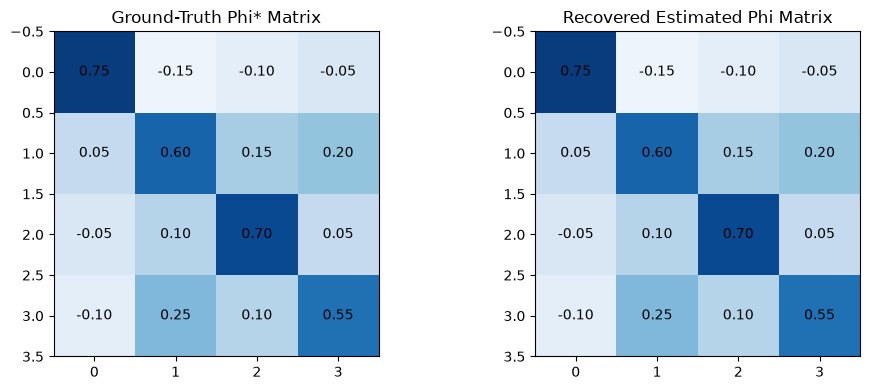

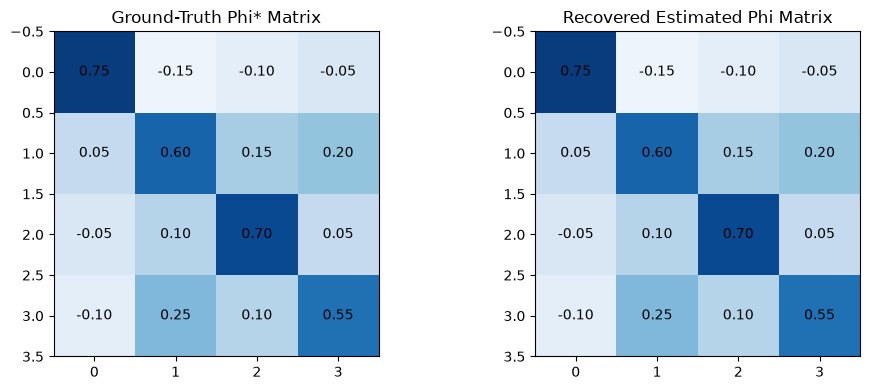

In [2]:
synth = eval_report['synthetic_recovery']
print(f"Synthetic Recovery Status: {'PASSED' if synth['recovered'] else 'FAILED'}")
print(f"- Max Relative Error: {synth['max_rel_error']:.4f} (Threshold: <= {synth['tolerance']:.2f})")
print(f"- Mean Relative Error: {synth['mean_rel_error']:.4f}")

phi_star = np.array(synth['phi_star'])
phi_hat = np.array(synth['phi_hat'])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4), dpi=100)
im1 = ax1.imshow(phi_star, cmap='Blues', vmin=-0.2, vmax=0.8)
ax1.set_title('Ground-Truth Phi* Matrix')
for i in range(4):
    for j in range(4):
        ax1.text(j, i, f'{phi_star[i, j]:.2f}', ha='center', va='center')

im2 = ax2.imshow(phi_hat, cmap='Blues', vmin=-0.2, vmax=0.8)
ax2.set_title('Recovered Estimated Phi Matrix')
for i in range(4):
    for j in range(4):
        ax2.text(j, i, f'{phi_hat[i, j]:.2f}', ha='center', va='center')

plt.tight_layout()
plt.show()

## 2. Empirical State Transition Matrix $\mathbf{\Phi}$
We inspect the learned inter-temporal cross-variable transition parameters governing macro system evolution.

In [3]:
phi_df = pd.DataFrame(model.phi_matrix_, index=model.state_cols, columns=[f'{c}_lag1' for c in model.state_cols])
display(phi_df.round(4))

print('Eigenvalues of Transition Matrix Phi (Stability Check):')
eigenvals = np.linalg.eigvals(model.phi_matrix_)
for ev in eigenvals:
    print(f"- Magnitude: {abs(ev):.4f} (Stable: {abs(ev) < 1.0})")

Eigenvalues of Transition Matrix Phi (Stability Check):
- Magnitude: 0.0259 (Stable: True)
- Magnitude: 0.8397 (Stable: True)
- Magnitude: 0.7727 (Stable: True)
- Magnitude: 0.7727 (Stable: True)


,weekly_order_volume_lag1,mean_delivery_delay_lag1,mean_freight_ratio_lag1,negative_review_rate_lag1
weekly_order_volume,0.7971,-0.0087,-0.0409,0.0459
mean_delivery_delay,0.0508,0.8168,-0.0235,-0.0230
mean_freight_ratio,-0.0527,-0.1183,0.0172,0.0955
negative_review_rate,0.0533,0.0795,0.2927,0.7279


## 3. Historical Replay Backtesting (2017–2018)
We evaluate the predictive accuracy of the World Model across 87 historical weeks.

In [4]:
metrics_df = pd.DataFrame(eval_report['backtest_metrics']).T
display(metrics_df[['wape', 'mape', 'rmse']].round(4))

display(Image(filename=str(REPO_ROOT / 'artifacts' / 'reports' / 'figures' / 'world_model_historical_replay.png')))

,wape,mape,rmse
weekly_order_volume,0.1583,0.2532,293.8098
mean_delivery_delay,0.1274,0.1480,2.3084
mean_freight_ratio,0.0418,0.0420,0.0165
negative_review_rate,0.1468,0.1532,0.0230
